In [3]:
import os
from dotenv import load_dotenv
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

# ---------------------------------------------------------
# 1. Connect to BigQuery
# ---------------------------------------------------------

load_dotenv()

# data_project = os.getenv("DATA_PROJECT_ID")
# dataset_id = os.getenv("DATASET_ID")
# billing_project = os.getenv("BILLING_PROJECT_ID")

# engine = create_engine(
#     f"bigquery://{billing_project}/{dataset_id}"
# )

project_id = os.getenv("GCP_PROJECT_ID")
dataset_id = os.getenv("GCP_DATASET_ID")

# SQLAlchemy BigQuery connection URI: bigquery://<project_id>/<dataset_id>
engine = create_engine(f"bigquery://{project_id}/{dataset_id}")

In [4]:


# ---------------------------------------------------------
# 2. Retrieve the latest one year of stock-return data
# ---------------------------------------------------------

query = f"""
SELECT
    f.date,
    f.ticker,
    d.company,
    d.sector,
    f.daily_return
FROM `{project_id}.{dataset_id}.fact_dailyprice` AS f
LEFT JOIN `{project_id}.{dataset_id}.dim_ticker` AS d

    ON f.ticker = d.ticker
WHERE
    f.date >= DATE_SUB(
        (
            SELECT MAX(date)
            FROM `{project_id}.{dataset_id}.fact_dailyprice`
        ),
        INTERVAL 1 YEAR
    )
    AND f.daily_return IS NOT NULL
    AND d.sector IS NOT NULL
ORDER BY
    f.date,
    f.ticker
"""

df = pd.read_sql(query, con=engine)

print("Rows retrieved:", len(df))
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Number of sectors:", df["sector"].nunique())

df.head()

Rows retrieved: 126163
Date range: 2025-10-08 to 2026-10-08
Number of sectors: 11


,date,ticker,company,sector,daily_return
0,2025-10-08,A,Agilent Technologies,Health Care,0.016238
1,2025-10-08,AAPL,Apple Inc.,Information Technology,0.006160
2,2025-10-08,ABBV,AbbVie,Health Care,-0.006829
3,2025-10-08,ABNB,Airbnb,Consumer Discretionary,0.001168
4,2025-10-08,ABT,Abbott Laboratories,Health Care,0.009397


In [5]:
# ---------------------------------------------------------
# 3. Calculate sector-level return and volatility
# ---------------------------------------------------------

sector_summary = (
    df.groupby("sector")
      .agg(
          average_daily_return=("daily_return", "mean"),
          daily_volatility=("daily_return", "std"),
          observations=("daily_return", "count"),
          stocks=("ticker", "nunique")
      )
      .reset_index()
)

# Convert decimal returns to percentages
sector_summary["average_daily_return_pct"] = (
    sector_summary["average_daily_return"] * 100
)

sector_summary["daily_volatility_pct"] = (
    sector_summary["daily_volatility"] * 100
)

# Keep the presentation columns
sector_summary = sector_summary[
    [
        "sector",
        "stocks",
        "observations",
        "average_daily_return_pct",
        "daily_volatility_pct"
    ]
]

# Sort from highest to lowest average daily return
sector_summary = sector_summary.sort_values(
    "average_daily_return_pct",
    ascending=False
).reset_index(drop=True)

sector_summary.round(4)

,sector,stocks,observations,average_daily_return_pct,daily_volatility_pct
0,Information Technology,75,18886,0.2060,3.6026
1,Energy,21,5292,0.1645,2.0774
2,Health Care,60,15120,0.0847,2.6306
3,Materials,24,6048,0.0593,2.3071
4,Industrials,83,20585,0.0458,2.3021
5,Consumer Staples,34,8321,0.0383,1.8485
6,Financials,76,19151,0.0154,1.9494
7,Real Estate,30,7560,-0.0062,1.6357
8,Utilities,31,7812,-0.0100,1.5530
9,Consumer Discretionary,47,11844,-0.0157,2.3115


In [8]:
import numpy as np
import matplotlib.pyplot as plt

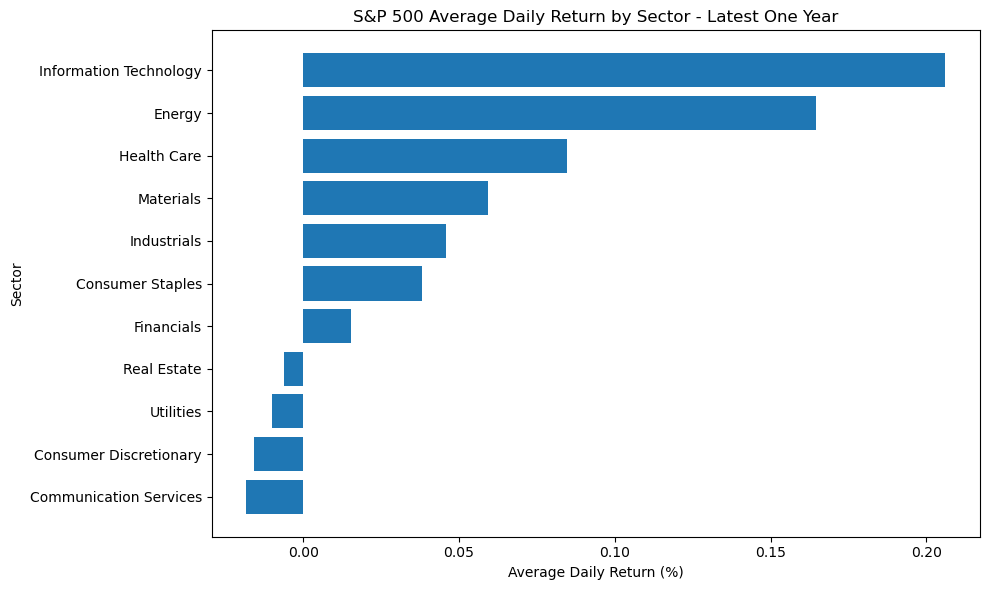

In [10]:
# ---------------------------------------------------------
# 4. Chart: average daily return by sector
# ---------------------------------------------------------

plot_df = sector_summary.sort_values(
    "average_daily_return_pct",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["sector"],
    plot_df["average_daily_return_pct"]
)

plt.xlabel("Average Daily Return (%)")
plt.ylabel("Sector")
plt.title("S&P 500 Average Daily Return by Sector - Latest One Year")

plt.tight_layout()
fig.savefig("images/sp500_avg_daily_return.png", dpi=300, bbox_inches="tight")
plt.show()

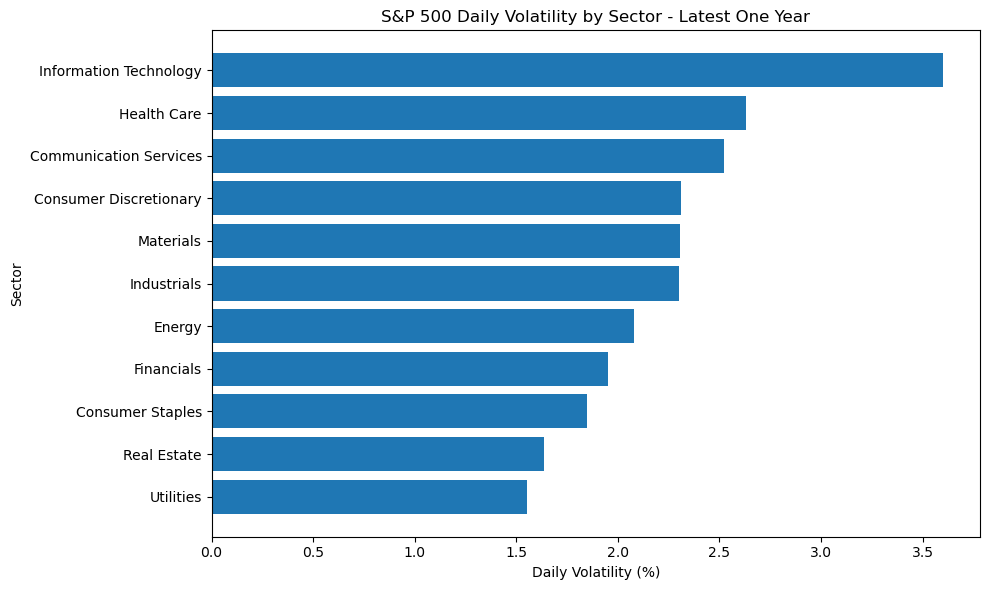

In [11]:
# ---------------------------------------------------------
# 5. Chart: daily volatility by sector
# ---------------------------------------------------------

plot_df = sector_summary.sort_values(
    "daily_volatility_pct",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["sector"],
    plot_df["daily_volatility_pct"]
)

plt.xlabel("Daily Volatility (%)")
plt.ylabel("Sector")
plt.title("S&P 500 Daily Volatility by Sector - Latest One Year")

plt.tight_layout()
fig.savefig("images/sp500_daily_volatility.png", dpi=300, bbox_inches="tight")
plt.show()